# Randomness and Trend Tests

Randomness tests each target a specific departure from an IID or white-noise null: linear autocorrelation (Ljung-Box), dependence in squares (McLeod-Li), too few or too many turning points, or monotone trend (Spearman rank). No single test proves randomness.

This notebook verifies the turning-point and runs examples from the note, implements the turning-point and Ljung-Box statistics, shows which test reacts to which kind of structure, and checks the multiple-testing illustration $1-(1-0.05)^{10}\approx0.401$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
get_ipython().run_line_magic("matplotlib", "inline")
from scipy import stats
from statsmodels.stats.diagnostic import acorr_ljungbox

rng = np.random.default_rng(7)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

def turning_points(x):
    x = np.asarray(x, float)
    mid = x[1:-1]
    return int(np.sum(((x[:-2] < mid) & (mid > x[2:])) | ((x[:-2] > mid) & (mid < x[2:]))))

def tp_test(x):
    n = len(x); T = turning_points(x)
    ET, VT = 2 * (n - 2) / 3, (16 * n - 29) / 90
    z = (T - ET) / np.sqrt(VT)
    return T, ET, VT, z, 2 * stats.norm.sf(abs(z))

def runs(signs):
    return 1 + int(np.sum(signs[1:] != signs[:-1]))

print("turning points of 1,3,2,4,3 :", turning_points([1, 3, 2, 4, 3]))
s = np.array(list("++--+--"))
print("runs of ++--+--             :", runs(s))
print("1-(1-0.05)^10               :", round(1 - 0.95**10, 3))

turning points of 1,3,2,4,3 : 3
runs of ++--+--             : 4
1-(1-0.05)^10               : 0.401


The counts match the note: $T=3$ turning points for $1,3,2,4,3$, four runs for $++--+--$, and a family-wise false-rejection probability of about $0.401$ for ten independent tests at level $0.05$.

## Turning-point test on different series

For a continuous IID series $E[T]=2(n-2)/3$ and $\mathrm{Var}(T)=(16n-29)/90$. A random walk has few turning points (persistence), while an alternating series has many.

series          T    E[T]  Var(T)       z        p
IID           206   198.7    53.0    1.01   0.3138
random walk   145   198.7    53.0   -7.37   0.0000
alternating   296   198.7    53.0   13.37   0.0000


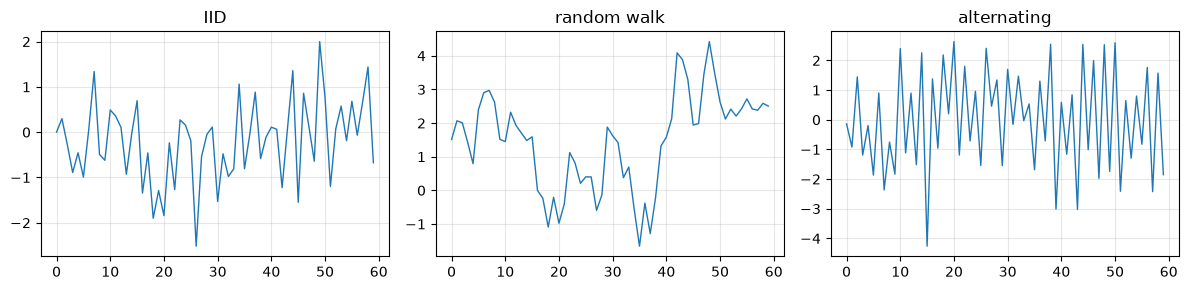

In [2]:
n = 300
iid = rng.normal(size=n)
walk = np.cumsum(rng.normal(size=n))
alt = rng.normal(size=n) + 1.5 * (-1.0) ** np.arange(n)     # alternating

print(f"{'series':<12}{'T':>5}{'E[T]':>8}{'Var(T)':>8}{'z':>8}{'p':>9}")
for name, x in [("IID", iid), ("random walk", walk), ("alternating", alt)]:
    T, ET, VT, z, p = tp_test(x)
    print(f"{name:<12}{T:>5d}{ET:>8.1f}{VT:>8.1f}{z:>8.2f}{p:>9.4f}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, (name, x) in zip(ax, [("IID", iid), ("random walk", walk), ("alternating", alt)]):
    a.plot(x[:60], lw=1); a.set_title(name)
plt.tight_layout(); plt.show()

The IID series sits near $E[T]=198$; the random walk has far too few turning points (large negative $z$), and the alternating series far too many (large positive $z$). The test flags the departure but does not name the mechanism.

## Ljung-Box and McLeod-Li: mean versus variance dependence

Ljung-Box on the series looks for linear autocorrelation; applying it to the squared series is the McLeod-Li test. We compare IID noise, an AR(1), and an ARCH-type series that is serially uncorrelated but has volatility clustering.

series      LB p (x)   McLeod-Li p (x^2)


IID           0.5009              0.9463
AR(1)     5.559e-152           4.437e-25
ARCH           0.337          1.317e-104


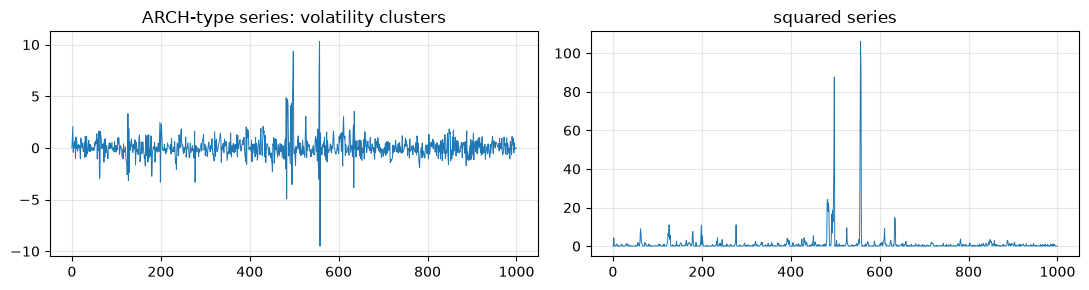

In [3]:
n = 1000
e = rng.normal(size=n)

ar1 = np.zeros(n)
for t in range(1, n):
    ar1[t] = 0.6 * ar1[t - 1] + e[t]

arch = np.zeros(n)
for t in range(1, n):
    arch[t] = e[t] * np.sqrt(0.2 + 0.8 * arch[t - 1] ** 2)

def lb_p(x, m=10):
    return acorr_ljungbox(x, lags=[m]).iloc[0]["lb_pvalue"]

print(f"{'series':<8}{'LB p (x)':>12}{'McLeod-Li p (x^2)':>20}")
for name, x in [("IID", e), ("AR(1)", ar1), ("ARCH", arch)]:
    print(f"{name:<8}{lb_p(x):>12.4g}{lb_p(x**2):>20.4g}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].plot(arch, lw=0.7); ax[0].set_title("ARCH-type series: volatility clusters")
ax[1].plot(arch**2, lw=0.7); ax[1].set_title("squared series")
plt.tight_layout(); plt.show()

The AR(1) series is caught by Ljung-Box on the levels. The ARCH-type series typically passes the levels test (little linear autocorrelation) but fails McLeod-Li on the squares, showing that the two diagnostics answer different questions.

## Spearman rank trend test

Spearman's $\rho_s$ between time and the values detects a monotone trend without normality. We apply it to noise, noise plus a weak linear trend, and compare with the closed-form rank formula.

In [4]:
n = 200
t = np.arange(1, n + 1)
noise = rng.normal(size=n)
trend = noise + 0.01 * t

for name, x in [("noise", noise), ("noise + trend", trend)]:
    rho, p = stats.spearmanr(t, x)
    r = stats.rankdata(x)
    rho_formula = 1 - 6 * np.sum((r - t) ** 2) / (n * (n**2 - 1))
    print(f"{name:<14} rho_s={rho:6.3f}  formula={rho_formula:6.3f}  p={p:.3g}")

# false-rejection rate when running K tests at 5% on IID series
K, reps = 10, 2000
rej = 0
for _ in range(reps):
    pv = [stats.spearmanr(np.arange(60), rng.normal(size=60))[1] for _ in range(K)]
    rej += min(pv) < 0.05
print("P(at least one of 10 rejects), simulated:", rej / reps, " theory:", round(1 - 0.95**10, 3))

noise          rho_s=-0.026  formula=-0.026  p=0.711
noise + trend  rho_s= 0.479  formula= 0.479  p=7.22e-13


P(at least one of 10 rejects), simulated: 0.4045  theory: 0.401


The rank formula agrees with the library value, the trended series gives a clearly nonzero $\rho_s$, and the simulated chance of at least one false rejection among ten tests is close to $0.40$ (these tests are independent here because the series are independent). Real diagnostics on one series are dependent, so treat such p-values as related evidence, not independent discoveries.